# 04. Context engineering

## Problem

A long recovery investigation fills the model input with archives and loses the unresolved question about joint authority. Reduce context while preserving evidence and constraints.

## Learning objectives

Allocate a context budget; preserve required passages; offload and reread bulky results; trim complete turns; compact state; distinguish prompt caching from memory.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Context is not memory

An LLM has no automatic persistent access to earlier application events.

For each inference, the application constructs the model-visible input:

$$ C = I + H + T + E + W $$

Where:

- $ I $: instructions
- $ H $: retained conversation history
- $ T $: tool definitions and messages
- $ E $: retrieved evidence
- $ W $: relevant working-state information

These components compete for a finite context budget.

The engineering problem is not simply making the context shorter. It is **keeping the information needed for the next decision while retaining access to the original evidence**.

Imagine an incident investigator's desk. The desk holds the material currently being read. A filing cabinet holds original records. A notebook contains the investigator's current conclusions and open questions.

You would not place every historical incident report on the desk simultaneously.

Similarly, an agent needs a small active context, durable reference material, and structured working state.

## Five context strategies

| Strategy            | Mechanism                                 | Appropriate use              |
| ------------------- | ----------------------------------------- | ---------------------------- |
| Selective retrieval | Include only relevant passages            | Every research question      |
| Offloading          | Store bulky results outside model context | Large search or tool outputs |
| Trimming            | Remove older or redundant messages        | Repetitive exchanges         |
| Summarization       | Condense earlier conversation             | Long-running work            |
| Context isolation   | Use child-agent contexts                  | Independent complex subtasks |

These strategies are complementary.

The repository's context lab already demonstrates offloading a large result and returning a file pointer. Its summarization lab demonstrates a compacted history and retained checkpoint state.

The important extension is to make the preservation policy explicit.

## What a summary must preserve

A poor Northstar summary might say:

> We reviewed recovery procedures and found the responsible teams.

That loses the information necessary to continue safely.

A useful summary should preserve:

```
{
  "objective": "Prepare a SEV-1 recovery readiness brief",
  "confirmed_facts": [
    {
      "fact": "Restore requires Database Operations Lead approval",
      "evidence_id": "BKP-7#p12",
      "revision": "4"
    }
  ],
  "constraints": [
    "Do not infer a shared approval process without evidence"
  ],
  "decisions": [
    "Separate restore authorization from incident coordination"
  ],
  "unresolved_questions": [
    "Does a combined approval procedure exist?"
  ],
  "working_files": [
    "/drafts/recovery-brief.md"
  ]
}
```

This is significantly more useful than a generic narrative summary.

However, the summary is still not the source of truth. Exact quotations, timestamps, revisions, and approval decisions must remain available in their authoritative records.

## Implementation: bounded evidence context

### **Code walkthrough**

The `ContextBudget` object records how the application intends to allocate space. It does not make a model's context window larger.

The `approximate_tokens()` function is a teaching heuristic. Production usage accounting should use the actual provider tokenizer or the provider's reported token counts.

`select_evidence()` reserves required passages, then greedily chooses optional passages by relevance. It is intentionally simple.

In a mature system, selection should also consider source diversity, required evidence IDs, contradictions, authority, recency, and the marginal usefulness of additional passages.

The notebook's offload exercise stores the full set for future inspection. In a multi-tenant application, the path must be generated inside an authorized, scoped workspace rather than accepted directly from model output.

### **Selective rereading**

Once a large file is offloaded, the agent should retrieve only the necessary portion:

This is an educational implementation. In Northstar's real filesystem abstraction, use the permitted file-reading tools rather than arbitrary host paths.

## Prompt caching is not memory

Prompt caching may allow a model provider to reuse computation associated with an unchanged prompt prefix.

It can reduce processing cost or latency when supported and applicable. It does not mean the model independently remembers information between requests.

| Mechanism            | What persists                               |
| -------------------- | ------------------------------------------- |
| Prompt caching       | Reusable provider-side computation          |
| Conversation history | Messages the application retains            |
| Checkpoint           | Saved runtime state                         |
| Working file         | External content accessible through tools   |
| Long-term memory     | Application-managed information across runs |

Cache behavior, minimum eligible sizes, retention, and usage reporting are provider-specific.

Do not build correctness assumptions around a prompt-cache hit.

## Context experiment

Run the same Northstar evaluation cases with four configurations.

| Experiment | Context strategy                             |
| ---------- | -------------------------------------------- |
| C1         | All retrieved passages included              |
| C2         | Top four passages only                       |
| C3         | Selected evidence plus file offloading       |
| C4         | Selected evidence plus structured compaction |

Measure task success, expected-evidence recall, claim support, input-token consumption, and total latency.

The key hypothesis is not that fewer tokens always improve accuracy.

It is that **task-aware context selection can reduce wasted context without losing required evidence**.

A possible outcome is that C2 uses fewer tokens but misses a contradictory source. That would be an unacceptable regression even if its answers become faster.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

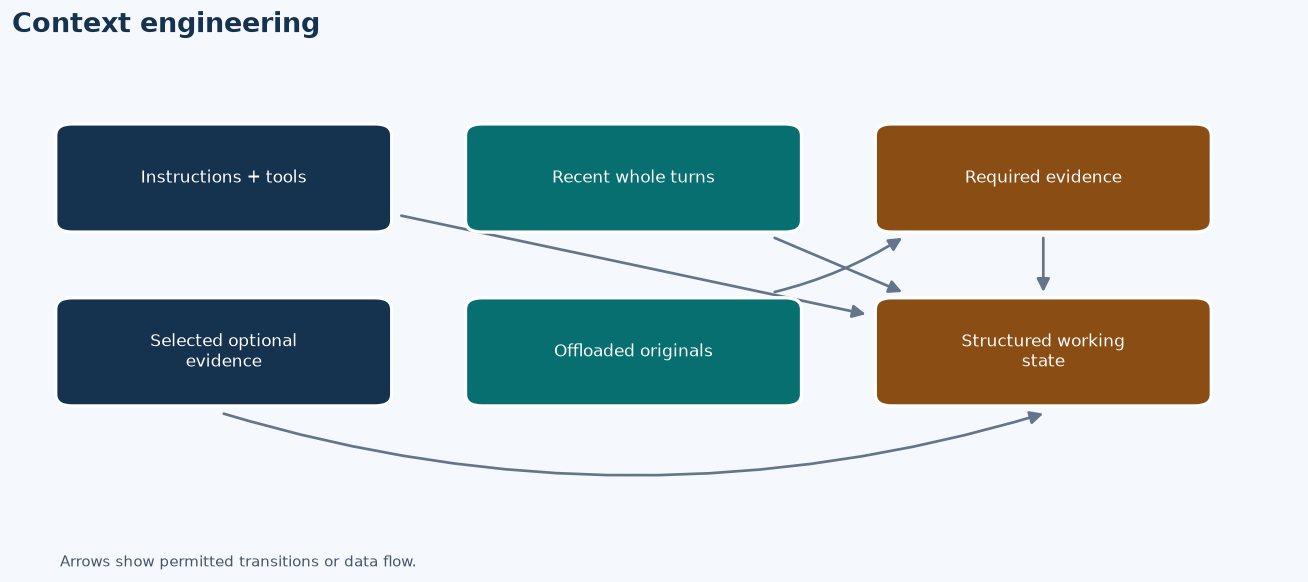

In [2]:
display(diagram('Context engineering', ['Instructions + tools', 'Recent whole turns', 'Required evidence', 'Selected optional evidence', 'Offloaded originals', 'Structured working state'], [(0, 5), (1, 5), (2, 5), (3, 5), (4, 2)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import json
from deep_agent_lab.context import approximate_tokens, ContextBudget, select_evidence
from deep_agent_lab.knowledge import fixture_search
rows = [row.model_dump() for row in fixture_search("restore incident access recovery", 5)]
required = frozenset({"northstar-restore", "northstar-incident"})

# Implement the invariant before the optimization.
def select_required_first(rows, required, allowance):
    selected = [row for row in rows if row["id"] in required]
    cost = sum(approximate_tokens(json.dumps(row, sort_keys=True)) for row in selected)
    if cost > allowance:
        raise ValueError("Required evidence does not fit")
    for row in rows:
        item_cost = approximate_tokens(json.dumps(row, sort_keys=True))
        if row["id"] not in required and cost + item_cost <= allowance:
            selected.append(row)
            cost += item_cost
    return selected

allowance = ContextBudget(window=1600, instructions=500, history=300, output=400, headroom=100).evidence_allowance
selected = select_required_first(rows, required, allowance)
assert required <= {row["id"] for row in selected}
print("Evidence allowance (estimated tokens):", allowance)

Evidence allowance (estimated tokens): 300


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.labs import context_lab, summarization_lab
offload = context_lab()
summary = summarization_lab()
assert offload["files"][0].startswith("/large_tool_results/")
assert summary["files"] == ["/conversation_history/summary-lab.md"]
print("Real filesystem middleware offload:", offload["files"])
print("Real summarization middleware history:", summary["files"])
from deep_agent_lab.context import WorkingState, compact, validate_compaction, trim_turns, prefix_key
state = WorkingState(objective="Readiness brief", constraints=["Do not infer joint authority"],
                     evidence_revisions={row["id"]: row["revision"] for row in rows},
                     unresolved=["Does a combined approval procedure exist?"], files=["/draft.md"])
compacted = compact(state, "Restore and incident policies were inspected.")
validate_compaction(state, compacted)

Real filesystem middleware offload: ['/large_tool_results/fetch_archive']
Real summarization middleware history: ['/conversation_history/summary-lab.md']


## Code walkthrough

The allowance reserves output and safety headroom before selecting evidence. The UTF-8 length heuristic is diagnostic and is not an Ollama tokenizer. Required evidence is charged before optional passages; budget exhaustion becomes an explicit exception. Real Deep Agents middleware offloads results into virtual storage and summarizes history. Our structured compaction copies source revisions, constraints, decisions and open questions without asking a model to rewrite them. Prompt prefix fingerprints identify stable inputs; actual KV-cache reuse is provider behavior.

## Interactive experiments

Compare C1 all evidence, C2 the first passage only, C3 selected evidence plus offloaded originals, and C4 the same selection with structured compaction. The measurements below are evidence recall and estimated context size, not model accuracy.

C1 all required-evidence recall: 1.0 estimated tokens: 422
C2 first required-evidence recall: 0.5 estimated tokens: 110
C3 selected required-evidence recall: 1.0 estimated tokens: 217
C4 compacted required-evidence recall: 1.0 estimated tokens: 217


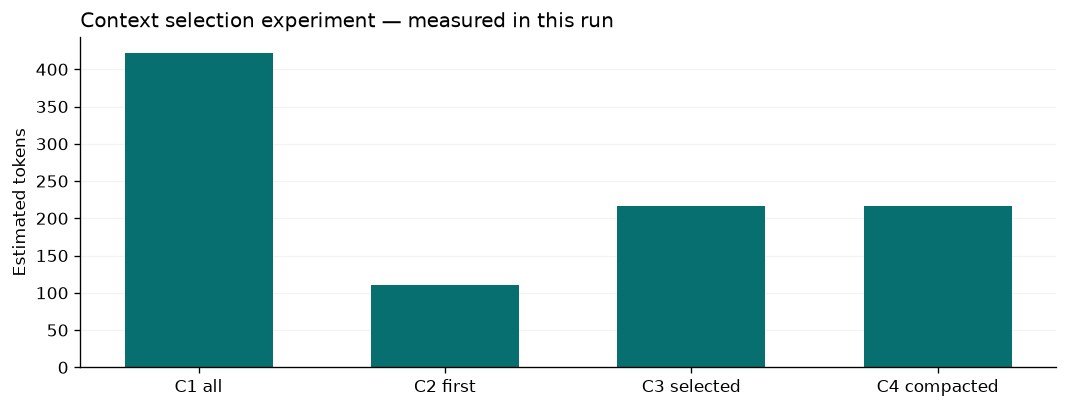

In [5]:
strategies = {"C1 all": rows, "C2 first": rows[:1],
              "C3 selected": select_evidence(rows, allowance, required),
              "C4 compacted": select_evidence(rows, allowance, required)}
measurements = {}
for name, visible in strategies.items():
    recall = len(required & {row["id"] for row in visible}) / len(required)
    measurements[name] = approximate_tokens(json.dumps(visible))
    print(name, "required-evidence recall:", recall, "estimated tokens:", measurements[name])
assert len(required & {row["id"] for row in strategies["C2 first"]}) < len(required)
display(bars("Context selection experiment", measurements, ylabel="Estimated tokens"))
plt.close("all")

## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
broken = compacted.model_copy(deep=True)
broken.unresolved.clear()
try:
    validate_compaction(state, broken)
except ValueError as error:
    print("Expected lost-question detection:", error)
else:
    raise AssertionError("Compaction silently lost the question")
try:
    select_evidence(rows, 1, required)
except ValueError:
    print("Expected: required evidence cannot be silently discarded to fit.")

Expected lost-question detection: Compaction lost required state
Expected: required evidence cannot be silently discarded to fit.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert state.unresolved == compacted.unresolved
assert prefix_key("fixed", {"search": 1}) == prefix_key("fixed", {"search": 1})
assert prefix_key("fixed", {"search": 1}) != prefix_key("changed", {"search": 1})
turns = [[{"role": "user", "content": "old " * 100}],
         [{"role": "assistant", "id": "c1"}, {"role": "tool", "tool_call_id": "c1"}]]
assert trim_turns(turns, 100) == turns[-1:]

## Exercise

Offload the evidence to a generated file inside the notebook's temporary workspace, reread two lines, and verify the source revision still appears. In an agent run, use its permitted virtual read_file tool with offset and limit.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
archive = Path(scratch.name) / "evidence.jsonl"
archive.write_text("\n".join(json.dumps(row) for row in rows), encoding="utf-8")
def read_lines(path, offset=0, limit=2):
    if offset < 0 or not 1 <= limit <= 100:
        raise ValueError("Invalid read range")
    return path.read_text(encoding="utf-8").splitlines()[offset:offset+limit]
assert len(read_lines(archive)) == 2
assert json.loads(read_lines(archive)[0])["revision"]

## Trade-offs and further reading

A shorter prompt can lose decisive counterevidence. Measure evidence retention separately from latency. Summaries are working aids; original records remain the authority for quotations, policy revisions and approvals.

[Primary source 1](https://docs.langchain.com/oss/python/deepagents/context-engineering) · [Primary source 2](https://www.anthropic.com/research/effective-context-engineering-for-ai-agents)

In [9]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
